# Momento de Retroalimentación: Módulo 5 Implementación de un modelo de deep learning

## 1. Introducción

### El problema
Un celular trae dos sensores pequeños: un **acelerómetro**, que siente hacia dónde y qué tan fuerte se mueve el teléfono,
y un **giroscopio**, que siente cuándo gira. Si alguien lleva el celular en la cintura, esos sensores "sienten" de forma distinta
cuando la persona camina, sube escaleras, está sentada o está acostada.

La pregunta de este notebook es: **¿podemos enseñarle a una computadora a adivinar la actividad solo mirando esas lecturas?**

Las actividades posibles son seis:

| En los datos | Significa |
|---|---|
| `WALKING` | caminar |
| `WALKING_UPSTAIRS` | subir escaleras |
| `WALKING_DOWNSTAIRS` | bajar escaleras |
| `SITTING` | estar sentado |
| `STANDING` | estar de pie |
| `LAYING` | estar acostado |

### ¿Por qué importa?
Reconocer actividades de forma automática está detrás de cosas que usamos a diario:
- **Salud y bienestar:** las apps y relojes que cuentan pasos, minutos activos o cuánto tiempo pasaste sentado.
- **Cuidado de adultos mayores:** detectar si una persona dejó de moverse o pasó mucho tiempo acostada en un horario poco común.
- **Rehabilitación:** saber si un paciente está haciendo la actividad física que le indicaron.
- **Ahorro de batería y contexto:** el celular puede cambiar su comportamiento si sabe que vas caminando o que está quieto.

La dificultad es que **cada persona se mueve distinto**, así que el modelo tiene que funcionar con personas que nunca vio.

### Cómo se va a resolver
Se usó una **red neuronal convolucional**: un programa que *aprende* sus propias reglas viendo muchos ejemplos ya resueltos.

## 2. Datos

### 2.1 Dataset
El conjunto de datos es **"Human Activity Recognition Using Smartphones"**.
- Versión en CSV usada aquí (Kaggle): https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones

Un detalle importante: los creadores ya resumieron cada momento en **561 números**: promedios, qué tanto variaba la señal, valores máximos, medidas de frecuencia, etc. Cada fila del archivo es uno de esos momentos. Además hay dos columnas extra: quién era la persona (`subject`) y qué estaba haciendo (`Activity`).

Los datos ya vienen divididos por los autores:
- `train.csv`: 7,352 momentos de 21 personas.
- `test.csv`: 2,947 momentos de otras 9 personas.

### 2.2 Herramientas y los datos
En la siguiente celda traemos las librerías que vamos a usar:
- **pandas y numpy** para leer y manejar tablas de números.
- **TensorFlow / Keras** para construir y entrenar la red neuronal.
- **scikit-learn** para tareas de apoyo: separar los datos y medir qué tan bien le fue al modelo.
- **matplotlib y seaborn** para hacer gráficas.

Se usó semilla.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

train = pd.read_csv("datos/train.csv")
test = pd.read_csv("datos/test.csv")
print("Entrenamiento:", train.shape, "  Prueba:", test.shape)
train.iloc[:5, list(range(6)) + [-2, -1]]

Entrenamiento: (7352, 563)   Prueba: (2947, 563)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,1,STANDING


Cada archivo tiene **563 columnas**: las 561 medidas, la persona y la actividad.

Las columnas siguen un orden fijo: ej. **qué señal** (`tBodyAcc` = aceleración del cuerpo), **qué medida** (`mean` = promedio) y **qué eje** (X, Y o Z). Las columnas que hablan de lo mismo están una junto a otra.

### 2.3 Análisis de los datos
Antes de entrenar, se revisaron los datos.

Valores faltantes (entrenamiento / prueba): 0 / 0
Filas repetidas en entrenamiento: 0
Rango de los valores: de -1.0 a 1.0
Personas en entrenamiento: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Personas en prueba:        [2, 4, 9, 10, 12, 13, 18, 20, 24]


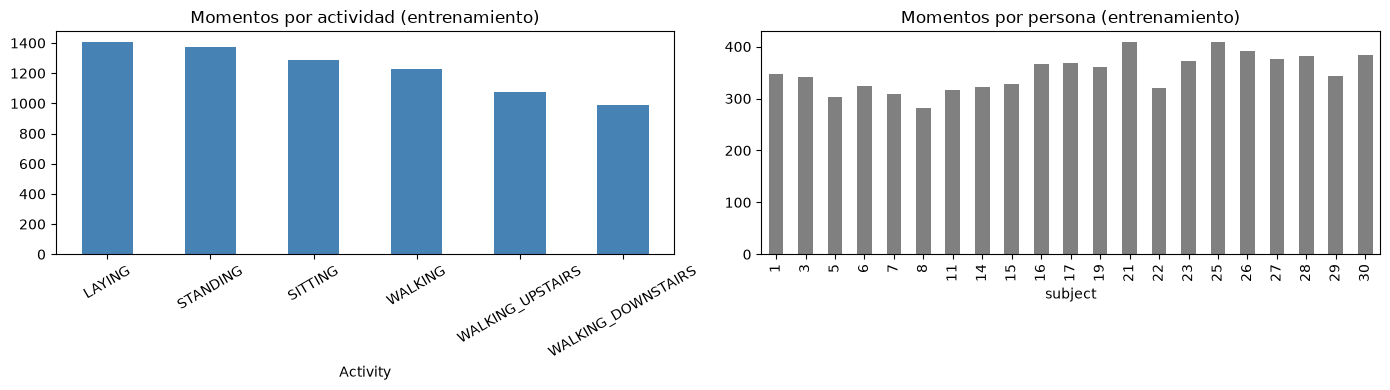

In [2]:
X_desc = train.drop(columns=["subject", "Activity"])
print("Valores faltantes (entrenamiento / prueba):", train.isna().sum().sum(), "/", test.isna().sum().sum())
print("Filas repetidas en entrenamiento:", train.duplicated().sum())
print(f"Rango de los valores: de {X_desc.min().min():.1f} a {X_desc.max().max():.1f}")
print("Personas en entrenamiento:", sorted(train["subject"].unique().tolist()))
print("Personas en prueba:       ", sorted(test["subject"].unique().tolist()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train["Activity"].value_counts().plot.bar(ax=ax[0], color="steelblue", title="Momentos por actividad (entrenamiento)")
train.groupby("subject").size().plot.bar(ax=ax[1], color="gray", title="Momentos por persona (entrenamiento)")
ax[0].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Lo que se encontró:
- No faltan valores ni hay filas repetidas. No hay que limpiar nada.
- Todos los números están entre −1 y 1.
- Las personas de entrenamiento y de prueba son distintas.
- Cada persona aporta una cantidad parecida de momentos (entre ~280 y ~410), así que ninguna domina el entrenamiento.

### 2.4 Separación y preparación de los datos

In [4]:
X = train.drop(columns=["subject", "Activity"]).values
y_txt = train["Activity"].values
X_test = test.drop(columns=["subject", "Activity"]).values

le = LabelEncoder().fit(y_txt)
y = le.transform(y_txt)
y_test = le.transform(test["Activity"].values)
clases = le.classes_

idx_tr, idx_val = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                       .split(X, y, groups=train["subject"]))
scaler = StandardScaler().fit(X[idx_tr])
prep = lambda a: scaler.transform(a)[..., np.newaxis]

X_tr, y_tr = prep(X[idx_tr]), y[idx_tr]
X_val, y_val = prep(X[idx_val]), y[idx_val]
X_te = prep(X_test)
print("train:", X_tr.shape, " val:", X_val.shape, " test:", X_te.shape)

train: (5551, 561, 1)  val: (1801, 561, 1)  test: (2947, 561, 1)


Quedaron ~5,500 momentos para aprender, ~1,800 para practicar y 2,947 para la validación final.

## 3. Desarrollo del modelo

### 3.1 Funciones de apoyo
La celda define tres funciones que se a reutilizarán con todos los modelos, para no repetir código:

- **`entrenar`**: pone a aprender al modelo. Le enseña los ejemplos en grupos de 64 y repite todo el conjunto varias
  veces. A cada repetición completa se le llama **época**. Al final de cada época, el modelo hace su examen de práctica.
- **`curvas`**: dibuja cómo fue mejorando el modelo época tras época, tanto en lo que aprende como en el examen de práctica.
- **`evaluar`**: mide el **porcentaje de aciertos** (*accuracy*) en los tres grupos y lo guarda para comparar los modelos al final.

In [5]:
def entrenar(modelo, epochs, callbacks=None):
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = modelo.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs,
                   batch_size=64, callbacks=callbacks, verbose=0)
    return h

def curvas(h, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(["loss", "accuracy"]):
        ax[i].plot(h.history[m], label="entrenamiento")
        ax[i].plot(h.history["val_" + m], label="validación")
        ax[i].set_title(f"{titulo} - {m}"); ax[i].set_xlabel("época"); ax[i].legend()
    plt.show()

resultados = {}
def evaluar(modelo, nombre):
    acc_tr = modelo.evaluate(X_tr, y_tr, verbose=0)[1]
    acc_val = modelo.evaluate(X_val, y_val, verbose=0)[1]
    acc_te = modelo.evaluate(X_te, y_test, verbose=0)[1]
    resultados[nombre] = {"train": acc_tr, "validación": acc_val, "prueba": acc_te,
                          "parámetros": modelo.count_params()}
    print(f"{nombre}: train={acc_tr:.4f}  val={acc_val:.4f}  test={acc_te:.4f}")

### 3.2 Entrenamiento y evaluación
Este primer modelo se entrena **40 épocas**, sin ninguna protección contra la memorización.

Model: "base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 557, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 278, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 274, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 137, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8768)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       561,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 572,102 (2.18 MB)

 Trainable params: 572,102 (2.18 MB)

 Non-trainable params: 0 (0.00 B)

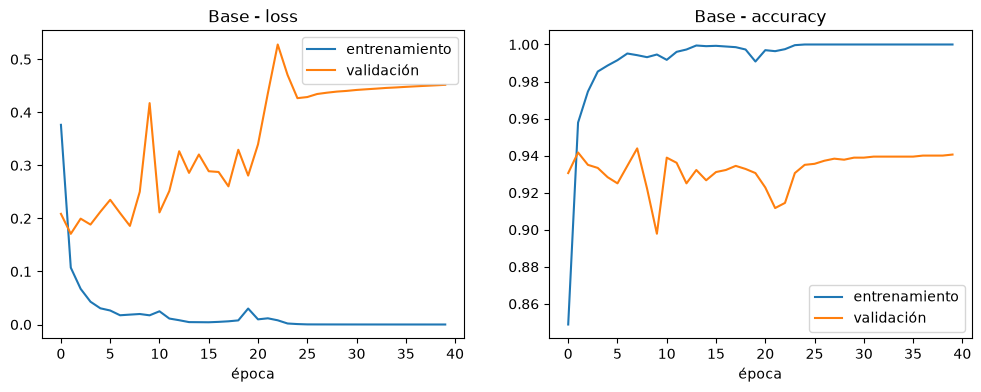

1. Base: train=1.0000  val=0.9406  test=0.9552


In [6]:
def modelo_base():
    return keras.Sequential([
        layers.Input((561, 1)),
        layers.Conv1D(32, 5, activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, activation="relu"),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(6, activation="softmax"),
    ], name="base")

m1 = modelo_base()
m1.summary()
h1 = entrenar(m1, epochs=40)
curvas(h1, "Base")
evaluar(m1, "1. Base")

El modelo acertó el **100% en los datos con los que aprendió**, pero ~94% en la práctica y ~95.5% en la validación.

Es importante aclarar que en este punto 100% es una señal de **overfitting**.

El siguiente paso es ponerle límites para que no pueda memorizar tan fácilmente.

## 4. Ajuste del modelo

Se hicieron tres rondas de ajustes.

### 4.1 Ponerle límites para que no memorice (regularización)

Se agregaron 3 capas de regularización.

**1. Apagar neuronas al azar (*Dropout*).**

**2. Castigar los valores exagerados (L2).**

**3. Parar a tiempo (*EarlyStopping*).**

Se inicializa con 100 épocas, pero el entrenamiento casi siempre se detiene antes por el earlystopping

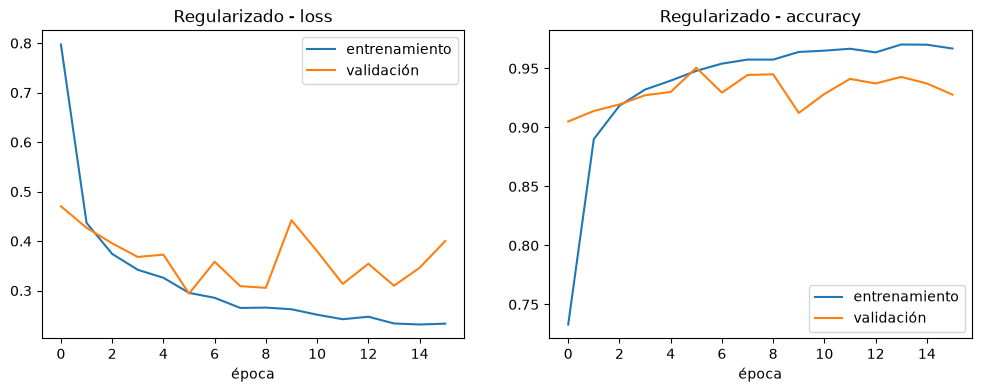

2. + Regularización: train=0.9782  val=0.9506  test=0.9440


In [7]:
def modelo_reg(l2=1e-3, nombre="regularizado"):
    reg = regularizers.l2(l2)
    return keras.Sequential([
        layers.Input((561, 1)),
        layers.Conv1D(32, 5, activation="relu", kernel_regularizer=reg),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, activation="relu", kernel_regularizer=reg),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu", kernel_regularizer=reg),
        layers.Dropout(0.5),
        layers.Dense(6, activation="softmax"),
    ], name=nombre)

early = lambda: keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

m2 = modelo_reg()
h2 = entrenar(m2, epochs=100, callbacks=[early()])
curvas(h2, "Regularizado")
evaluar(m2, "2. + Regularización")

### ANálisis

El acierto en entrenamiento **bajó de 100% a ~98%**. El modelo **ya no está memorizando**, y la distancia entre lo que aprende y lo que acierta con personas nuevas se hizo más pequeña.

### 4.2 Segunda ronda: cambiar la arquitectura

Se probó un diseño que se usa mucho en otros problemas:

- **128 filtros** (kernel)
- **Normalización entre capas** (*BatchNormalization*)
- **Promedio global** (*GlobalAveragePooling*)
- **Bajar la velocidad de aprendizaje cuando se estanca** (*ReduceLROnPlateau*)

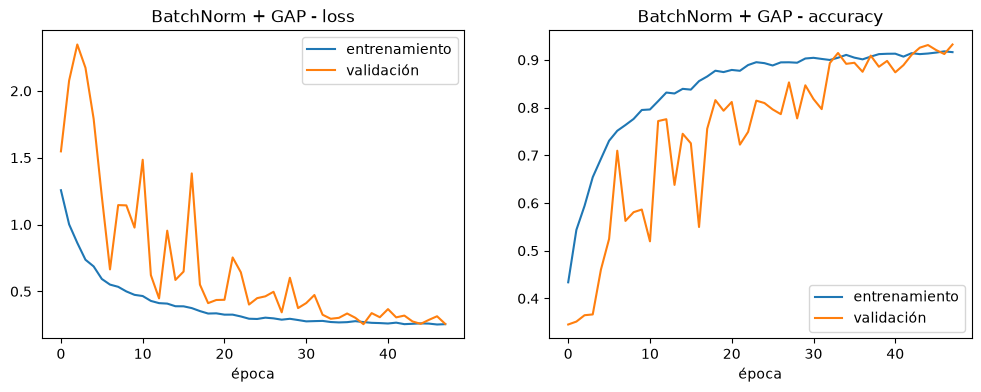

3. BatchNorm + GAP (descartado): train=0.9119  val=0.9089  test=0.8476


In [8]:
def modelo_gap(l2=1e-4):
    reg = regularizers.l2(l2)
    def bloque(x, filtros, k, pool=True):
        x = layers.Conv1D(filtros, k, padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        return layers.MaxPooling1D(2)(x) if pool else x

    entrada = layers.Input((561, 1))
    x = bloque(entrada, 64, 7)
    x = bloque(x, 128, 5)
    x = bloque(x, 128, 3, pool=False)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(6, activation="softmax")(x)
    return keras.Model(entrada, salida, name="gap")

m3 = modelo_gap()
h3 = entrenar(m3, epochs=100, callbacks=[
    early(),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)])
curvas(h3, "BatchNorm + GAP")
evaluar(m3, "3. BatchNorm + GAP (descartado)")

### ¿Por qué empeoró el modelo?

La columna 1 es el promedio del movimiento de lado a lado; la columna 300 es una medida completamente distinta. Si un filtro se "enciende", es muy importante saber **en qué columna** lo hizo. Al promediar todo, el modelo pierde esa información. 

Se nota más en **sentado contra de pie**. La diferencia entre ellas está en detalles finos de columnas específicas. Este modelo confundía a la mayoría de las personas sentadas con personas de pie.

**¿Qué nos dice esto?** Agregar más capas o piezas sofisticadas no ayudó. El modelo ya tenía capacidad de sobra; el problema real es
otro: **funcionar bien con personas que nunca vio**.

### 4.3 Modelo final

2 cambios:

**1. Utilizar toda la data**
Hasta ahora se apartaba un grupo de personas solo para practicar. Ese grupo ya nos dijo **cuántas épocas conviene entrenar** antes de que el modelo empiece a memorizar. Así que ahora:
- primero entrenamos como antes, solo para averiguar la mejor cantidad de épocas;
- luego entrenamos un modelo nuevo **con las 21 personas**, durante esa cantidad de épocas.

**2. Ensamble**
Entrenamos **tres modelos iguales** (con regularización), cada uno con un punto de partida al azar distinto y se promedia lo que dicen los tres.

Como los datos cambiaron, también recalculamos el ajuste de escala con todas ellas.

In [9]:
scaler_full = StandardScaler().fit(X)
X_all = scaler_full.transform(X)[..., np.newaxis]
X_te_full = scaler_full.transform(X_test)[..., np.newaxis]

ensamble = []
for seed in (1, 2, 3):
    tf.keras.utils.set_random_seed(seed)
    m = modelo_reg()
    es = early()
    entrenar(m, epochs=100, callbacks=[es])
    mejor_epoca = es.best_epoch + 1

    tf.keras.utils.set_random_seed(seed)
    m_full = modelo_reg(nombre=f"cnn_semilla_{seed}")
    m_full.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m_full.fit(X_all, y, epochs=mejor_epoca, batch_size=64, verbose=0)
    acc = m_full.evaluate(X_te_full, y_test, verbose=0)[1]
    print(f"semilla {seed}: mejor época = {mejor_epoca}, accuracy prueba = {acc:.4f}")
    ensamble.append(m_full)

def predecir(Xs):
    return np.mean([m.predict(Xs, verbose=0) for m in ensamble], axis=0)

prob_te = predecir(X_te_full)
pred_te = prob_te.argmax(axis=1)
resultados["4. Ensamble 3× regularizado (todos los sujetos)"] = {
    "train": accuracy_score(y, predecir(X_all).argmax(axis=1)), "validación": np.nan,
    "prueba": accuracy_score(y_test, pred_te), "parámetros": sum(m.count_params() for m in ensamble)}
print(f"Ensamble: accuracy prueba = {accuracy_score(y_test, pred_te):.4f}")

semilla 1: mejor época = 15, accuracy prueba = 0.9559


semilla 2: mejor época = 10, accuracy prueba = 0.9518


semilla 3: mejor época = 6, accuracy prueba = 0.9457


Ensamble: accuracy prueba = 0.9562


### Análisis

Cada modelo por separado sacó entre **94.6% y 95.6%** en el test (solo por el random inicial)

Juntos, promediando sus opiniones, sacan **95.6%**: un poco más que el mejor de los tres por separado. 

### 4.4 Comparación de todas las rondas

El modelo final no tiene número de validación porque esas personas pasaron a formar parte del aprendizaje.
Tiene tres veces más parámetros que el modelo con regularización porque son tres modelos juntos.

In [10]:
tabla = pd.DataFrame(resultados).T
tabla["brecha train-test"] = tabla["train"] - tabla["prueba"]
tabla.style.format({"train": "{:.4f}", "validación": "{:.4f}", "prueba": "{:.4f}",
                    "brecha train-test": "{:.4f}", "parámetros": "{:,.0f}"}, na_rep="—")

,train,validación,prueba,parámetros,brecha train-test
1. Base,1.0000,0.9406,0.9552,"572,102",0.0448
2. + Regularización,0.9782,0.9506,0.9440,"572,102",0.0342
3. BatchNorm + GAP (descartado),0.9119,0.9089,0.8476,"100,806",0.0643
4. Ensamble 3× regularizado (todos los sujetos),0.9918,—,0.9562,"1,716,306",0.0356


Lo que muestra la tabla:
- El **primer modelo** llega al 100% en lo aprendido y tiene una brecha grande con el test *(overfitting)*
- La **regularización** achica esa brecha *(disminuye overfitting)*.
- El **promedio global** es claramente el peor en el test. Como se mencionó, no se utilizó "lo importante", generando *(undefitting)*
- El **modelo final** tiene el mejor resultado en el tes, aunque por poco. Su verdadera ventaja es que, al combinar tres opiniones, es más confiable que cualquier modelo suelto.

## 5. Resultados

### 5.1 Guardar el modelo final
Hasta ahora el modelo final eran **tres piezas** más un ajuste de escala aparte. Para poder guardarlo y usarlo después,las juntamos en **un solo modelo** que hace todo el recorrido:

1. recibe los 561 números **tal como vienen en el CSV**;
2. les aplica el mismo ajuste de escala que usamos al entrenar;
3. se los pasa a las tres redes;
4. promedia sus tres respuestas.

Así, quien use el modelo no tiene que acordarse de escalar los datos ni de promediar: solo le pasa los números.
Lo guardamos en el archivo **`modelo_har_final.keras`**, que contiene la arquitectura y todos los valores aprendidos.

Al final la celda comprueba que el modelo empaquetado da **las mismas respuestas** que las tres piezas sueltas.
La diferencia debe ser prácticamente cero.

In [11]:
escalado = layers.Normalization(mean=scaler_full.mean_, variance=scaler_full.var_, name="escalado")
entrada = keras.Input((561,), name="caracteristicas")
x = layers.Reshape((561, 1), name="como_secuencia")(escalado(entrada))
salida = layers.Average(name="promedio_ensamble")([m(x) for m in ensamble])
modelo_final = keras.Model(entrada, salida, name="har_cnn1d_ensamble")

modelo_final.save("modelo_har_final.keras")
modelo_final.summary()

prob_final = modelo_final.predict(X_test.astype("float32"), verbose=0)
print("Diferencia máxima con las tres piezas sueltas:", np.abs(prob_final - prob_te).max())

Model: "har_cnn1d_ensamble"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caracteristicas     │ (None, 561)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ escalado            │ (None, 561)       │          0 │ caracteristicas[… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ como_secuencia      │ (None, 561, 1)    │          0 │ escalado[0][0]    │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_semilla_1       │ (None, 6)         │    572,102 │ como_secuencia[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_semilla_2       │ (None, 6)         │    572,102 │ como_secuencia[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_semilla_3       │ (None, 6)         │    572,102 │ como_secuencia[0… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_ensamble   │ (None, 6)         │          0 │ cnn_semilla_1[0]… │
│ (Average)           │                   │            │ cnn_semilla_2[0]… │
│                     │                   │            │ cnn_semilla_3[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,716,306 (6.55 MB)

 Trainable params: 1,716,306 (6.55 MB)

 Non-trainable params: 0 (0.00 B)

Diferencia máxima con las tres piezas sueltas: 4.172325e-07


### 5.2 Evaluación del modelo final con los datos de prueba
Test: las 2,947 filas de las 9 personas que el modelo nunca vio.

**El reporte por actividad tiene tres medidas:**
- **precision:**
- **recall:**
- **f1-score:**
**La matriz de confusión**

Accuracy del modelo final en prueba: 0.9562

                    precision    recall  f1-score   support

            LAYING     0.9963    1.0000    0.9981       537
           SITTING     0.9328    0.8758    0.9034       491
          STANDING     0.8946    0.9417    0.9176       532
           WALKING     0.9878    0.9778    0.9828       496
WALKING_DOWNSTAIRS     0.9730    0.9452    0.9589       420
  WALKING_UPSTAIRS     0.9590    0.9936    0.9760       471

          accuracy                         0.9562      2947
         macro avg     0.9573    0.9557    0.9561      2947
      weighted avg     0.9567    0.9562    0.9561      2947



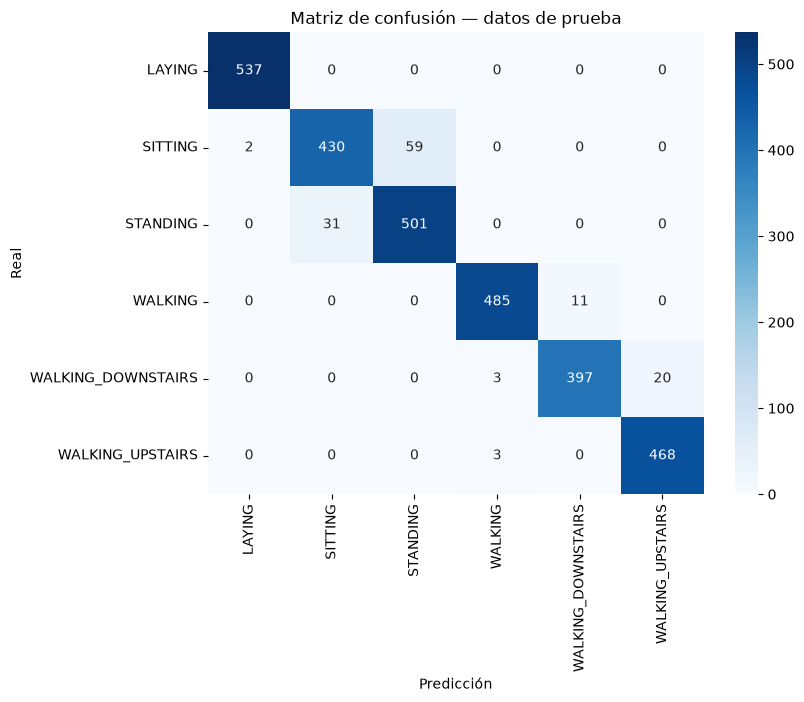

In [12]:
pred_final = prob_final.argmax(axis=1)
print(f"Accuracy del modelo final en prueba: {accuracy_score(y_test, pred_final):.4f}\n")
print(classification_report(y_test, pred_final, target_names=clases, digits=4))

cm = confusion_matrix(y_test, pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión — datos de prueba")
plt.show()

### ¿Qué nos dice?

- **Acostado** es casi perfecto. Como vimos en el análisis de datos, es la única postura en la que el celular queda horizontal, así que es muy fácil de distinguir.
- **Caminar, subir y bajar escaleras** también salen muy bien: las tres tienen movimiento, y el ritmo de cada una es distinto.
- **Casi todos los errores están entre sentado y de pie**, justo la confusión que anticipamos en la sección 2. En las dos la persona está quieta, con el celular vertical en la cintura, y los sensores ven algo muy parecido.
De las personas sentadas, el modelo reconoce ~88% (recall de 0.876); al resto lo confunde con "de pie".

## 6. Conclusiones

**El resultado:** el modelo final reconoce la actividad de **personas que nunca vio** en el **95.6%** de los casos.

### Lo que funcionó:
1. **Ponerle límites al modelo (regularización).** El primer modelo era tan grande que memorizaba los ejemplos *(overfitting)*.
2. **Aprender de más personas.** El reto principal no era la complejidad del modelo, sino que cada persona se mueve un poco distinto. Usar a las 21 personas para aprender ayudó a cubrir esa variedad.
3. **Escuchar a varios modelos (ensamble).** Un solo modelo cambia bastante dependiendo de su punto de partida al azar. Promediar tres opiniones da una respuesta más confiable.

### Lo que no funcionó, y por qué
- **Promediar todas las posiciones** destruyó la información de *qué columna* era cada número, que en estos datos es esencial. Una técnica que funciona muy bien con fotos puede fallar cuando los datos son de otra naturaleza.
- **Más capas y piezas sofisticadas** no ayudaron: el modelo ya tenía capacidad de sobra. Agregar complejidad no arregla un problema que no es de complejidad.
- **La memoria de secuencias (LSTM)** está pensada para datos que cambian en el tiempo, y cada fila de estos datos es un resumen ya calculado, no una secuencia en el tiempo.

### Qué se podría mejorar
- **Usar las señales originales de los sensores.** La fuente original también trae las lecturas en crudo: 128 instantes seguidos por momento.
  Ahí sí hay una secuencia en el tiempo, que es justo para lo que se diseñaron las convoluciones y las LSTM. El modelo podría encontrar patrones que los 561 resúmenes no capturan.
- **Distinguir mejor sentado de de pie.** Es casi todo el error que queda. Como los sensores de la cintura ven casi lo mismo en las dos posturas, probablemente se necesite otra información, por ejemplo un segundo sensor en el muslo o la muñeca.
- **Validar con más particiones de personas.** Aquí apartamos un solo grupo de personas para validar. Repetirlo con varios grupos distintos (validación cruzada por persona) daría decisiones más confiables.
- **Buscar hiperparámetros de forma sistemática.** El tamaño de las lupas, la cantidad de filtros o la fuerza de la regularización se eligieron con valores razonables, no con una búsqueda ordenada.
- **Más personas.** Con solo 21 personas para aprender, cada persona nueva puede moverse de una forma que el modelo no ha visto.

## 7. Aplicación: probar el modelo con datos nuevos

La función **`predecir_actividad`**:
- **recibe** la ruta a un archivo CSV con uno o varios momentos (cada fila con las 561 medidas);
- **carga** el modelo guardado en `modelo_har_final.keras`;
- **regresa** una tabla con la actividad que predice para cada fila y qué tan seguro está.

Si el CSV trae las columnas `subject` o `Activity`, la función las ignora: solo usa las 561 medidas.
El modelo devuelve las actividades en orden alfabético, así que la función usa ese mismo orden.

**Esta sección se puede correr sola**, sin ejecutar nada de lo anterior ni volver a entrenar: trae sus propias librerías y carga el modelo ya entrenado desde `modelo_har_final.keras`.

In [1]:
import numpy as np
import pandas as pd
from tensorflow import keras

ACTIVIDADES = {"LAYING": "acostado", "SITTING": "sentado", "STANDING": "de pie", "WALKING": "caminando",
               "WALKING_DOWNSTAIRS": "bajando escaleras", "WALKING_UPSTAIRS": "subiendo escaleras"}
NOMBRES = np.array(sorted(ACTIVIDADES))   # mismo orden (alfabético) en que el modelo da sus respuestas

def predecir_actividad(ruta_csv, ruta_modelo="modelo_har_final.keras"):
    """Recibe la ruta a un CSV con las 561 medidas de uno o varios momentos
    y regresa la actividad que predice el modelo para cada fila."""
    modelo = keras.models.load_model(ruta_modelo)
    datos = pd.read_csv(ruta_csv).drop(columns=["subject", "Activity"], errors="ignore")
    if datos.shape[1] != 561:
        raise ValueError(f"Se esperaban 561 columnas de medidas y el archivo trae {datos.shape[1]}.")
    prob = modelo.predict(datos.values.astype("float32"), verbose=0)
    actividad = NOMBRES[prob.argmax(axis=1)]
    return pd.DataFrame({"predicción": actividad,
                         "en español": [ACTIVIDADES[a] for a in actividad],
                         "confianza": prob.max(axis=1).round(4)})

print("Función lista. Actividades en el orden del modelo:", NOMBRES.tolist())

Función lista. Actividades en el orden del modelo: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


### Probándola
Para simular datos nuevos tomamos **10 momentos al azar** del conjunto de prueba (personas que el modelo nunca vio)
y los guardamos en `datos/ejemplos_nuevos.csv` **sin la columna de la respuesta**. Así el modelo no tiene forma de "ver" la actividad real.

Después le pasamos ese archivo a la función. A la tabla que regresa le pegamos la actividad real, **solo para comparar**.

In [2]:
test = pd.read_csv("datos/test.csv")
muestras = np.random.default_rng(7).choice(len(test), 10, replace=False)
nuevos = test.iloc[muestras]
nuevos.drop(columns=["Activity"]).to_csv("datos/ejemplos_nuevos.csv", index=False)
resultado = predecir_actividad("datos/ejemplos_nuevos.csv")
resultado.insert(0, "persona", nuevos["subject"].values)
resultado.insert(1, "real", nuevos["Activity"].values)
resultado["¿correcta?"] = np.where(resultado["predicción"] == resultado["real"], "sí", "no")
resultado

,persona,real,predicción,en español,confianza,¿correcta?
0,13,WALKING_UPSTAIRS,WALKING_UPSTAIRS,subiendo escaleras,0.9997,sí
1,24,LAYING,LAYING,acostado,1.0000,sí
2,20,SITTING,SITTING,sentado,0.7510,sí
3,20,SITTING,SITTING,sentado,0.7140,sí
4,13,STANDING,STANDING,de pie,0.9991,sí
5,9,WALKING_UPSTAIRS,WALKING_UPSTAIRS,subiendo escaleras,0.8098,sí
6,24,STANDING,STANDING,de pie,0.9937,sí
7,2,STANDING,STANDING,de pie,0.9922,sí
8,9,SITTING,SITTING,sentado,0.9859,sí
9,18,WALKING_UPSTAIRS,WALKING_UPSTAIRS,subiendo escaleras,0.9999,sí


### ¿Qué nos dice?

El modelo acierta los **10 ejemplos**. Lo más interesante es la columna de **confianza**:
- En "acostado" o "de pie" está casi seguro (0.99 o más).
- En dos de los ejemplos de **"sentado"** acierta, pero con menos seguridad (~0.71–0.75).

Eso concuerda con todo lo anterior: **"sentado" es la actividad que más le cuesta**, y el modelo "lo sabe", porque duda más justamente ahí. Que el modelo dude donde es más fácil equivocarse es una buena señal: su nivel de seguridad es honesto.